# Recursive NSPPK Feature Generation: HIV Tuning and Validation

This notebook tests whether importance-guided root filtering can retain useful HIV classification performance while reducing feature-generation time. The selected two-stage configuration is evaluated against multiple unfiltered NSPPK baselines over repeated stratified splits on a tuning cohort and a separately sampled validation cohort.

The tuning run selected 10% root retention, stage settings `(radius=1, distance=4, connector=0)` followed by `(radius=2, distance=4, connector=1)`, no simplex expansion in the final stage, importance quantile 0.5, and logistic-regression `C=0.01`. The notebook reports mean and standard deviation across held-out splits, plus individual-stage AUCs.


In [1]:
from pathlib import Path
import pickle
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import hstack
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(path for path in REPO_CANDIDATES if (path / 'src').exists())
SRC_DIR = REPO_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from nsppk import NSPPK
from recursive_nsppk import RecursiveNSPPKClassifier

RANDOM_STATE = 2026
NBITS = 12
SIMPLEX_FEATURE_ORDER = 2
SAMPLE_PER_CLASS = 100
TUNING_SAMPLE_SEED = 2026
VALIDATION_SAMPLE_SEED = 2027
TUNING_SPLIT_SEEDS = tuple(range(2026, 2031))
VALIDATION_SPLIT_SEEDS = (2026, 2027, 2028)
ROOT_RETENTION = 0.1
FINAL_MODEL_C = 0.01
IMPORTANCE_N_ITER = 3
IMPORTANCE_N_ESTIMATORS = 100
IMPORTANCE_QUANTILE = 0.5
HIV_PICKLE = REPO_ROOT / 'data' / 'HIV_networkx_graphs.pkl'


In [2]:
with HIV_PICKLE.open('rb') as handle:
    hiv_data = pickle.load(handle)
hiv_graphs_all = hiv_data['graphs']
hiv_labels_all = np.asarray(hiv_data['labels'], dtype=int)


def make_balanced_cohort(sample_seed):
    rng = np.random.default_rng(sample_seed)
    class_indices = [np.flatnonzero(hiv_labels_all == label) for label in (0, 1)]
    if any(len(indices) < SAMPLE_PER_CLASS for indices in class_indices):
        raise ValueError('SAMPLE_PER_CLASS exceeds the available examples in a class.')
    selected_indices = np.concatenate([
        rng.choice(indices, size=SAMPLE_PER_CLASS, replace=False)
        for indices in class_indices
    ])
    rng.shuffle(selected_indices)
    return [hiv_graphs_all[index] for index in selected_indices], hiv_labels_all[selected_indices]


cohorts = {
    'tuning': {
        'sample_seed': TUNING_SAMPLE_SEED,
        'split_seeds': TUNING_SPLIT_SEEDS,
    },
    'validation': {
        'sample_seed': VALIDATION_SAMPLE_SEED,
        'split_seeds': VALIDATION_SPLIT_SEEDS,
    },
}
for cohort_name, cohort in cohorts.items():
    cohort['graphs'], cohort['labels'] = make_balanced_cohort(cohort['sample_seed'])
    print(
        f"{cohort_name}: n={len(cohort['graphs'])}, "
        f"class counts={np.bincount(cohort['labels']).tolist()}, "
        f"stratified splits={len(cohort['split_seeds'])}"
    )


tuning: n=200, class counts=[100, 100], stratified splits=5
validation: n=200, class counts=[100, 100], stratified splits=3


## Tuned recursive settings and full-feature baselines

The tuning cohort used a small sweep over root-retention fractions, connector depth, importance quantile, and logistic `C`. The setting below was chosen for the AUC/runtime tradeoff, then checked on a separate balanced graph sample and different split seeds. Full-feature baselines are encoded once per cohort and reused across folds because their graph vectors do not depend on the labels or split.


In [3]:
STAGES = [
    {'radius': 1, 'distance': 4, 'connector': 0, 'use_simplex_features': False},
    {'radius': 2, 'distance': 4, 'connector': 1, 'use_simplex_features': False},
]
BASELINES = [
    {
        'name': 'All roots: stage 1 settings',
        'params': {'radius': 1, 'distance': 4, 'connector': 0, 'use_simplex_features': False},
    },
    {
        'name': 'All roots: stage 2 settings',
        'params': {'radius': 2, 'distance': 4, 'connector': 1, 'use_simplex_features': False},
    },
    {
        'name': 'All roots: stage 3 settings',
        'params': {'radius': 2, 'distance': 4, 'connector': 1, 'use_simplex_features': True},
    },
]


def make_classifier(seed):
    return LogisticRegression(
        solver='liblinear', max_iter=1000, class_weight='balanced',
        C=FINAL_MODEL_C, random_state=seed,
    )


def split_cohort(cohort, seed):
    train_indices, test_indices = train_test_split(
        np.arange(len(cohort['graphs'])), test_size=0.25,
        random_state=seed, stratify=cohort['labels'],
    )
    return train_indices, test_indices


## Encode and evaluate all-root baselines

For each cohort and baseline configuration, NSPPK features are generated once for the full sample. Each classifier is trained and scored on every corresponding stratified split.


In [4]:
baseline_auc_rows = []
baseline_runtime_rows = []
baseline_feature_matrices = {}
for cohort_name, cohort in cohorts.items():
    graphs = cohort['graphs']
    labels = cohort['labels']
    first_train, _ = split_cohort(cohort, cohort['split_seeds'][0])
    train_graphs = [graphs[index] for index in first_train]
    train_labels = labels[first_train]

    for baseline in BASELINES:
        encoder = NSPPK(
            **baseline['params'], nbits=NBITS, dense=False, parallel=False,
            simplex_feature_order=SIMPLEX_FEATURE_ORDER,
        )
        started = time.perf_counter()
        features = encoder.fit(train_graphs, train_labels).transform(graphs)
        feature_seconds = time.perf_counter() - started
        baseline_feature_matrices[(cohort_name, baseline['name'])] = features

        fold_fit_seconds = []
        fold_predict_seconds = []
        for split_seed in cohort['split_seeds']:
            train_indices, test_indices = split_cohort(cohort, split_seed)
            classifier = make_classifier(split_seed)
            started = time.perf_counter()
            classifier.fit(features[train_indices], labels[train_indices])
            fit_seconds = time.perf_counter() - started
            started = time.perf_counter()
            probabilities = classifier.predict_proba(features[test_indices])[:, 1]
            predict_seconds = time.perf_counter() - started
            auc = roc_auc_score(labels[test_indices], probabilities)
            baseline_auc_rows.append({
                'cohort': cohort_name,
                'split': split_seed,
                'configuration': baseline['name'],
                'ROC AUC': auc,
                'feature_nnz': int(features.nnz),
            })
            fold_fit_seconds.append(fit_seconds)
            fold_predict_seconds.append(predict_seconds)

        baseline_runtime_rows.append({
            'cohort': cohort_name,
            'configuration': baseline['name'],
            'feature_generation_sec': feature_seconds,
            'mean_classifier_fit_sec': float(np.mean(fold_fit_seconds)),
            'mean_prediction_sec': float(np.mean(fold_predict_seconds)),
            'split_count': len(cohort['split_seeds']),
        })
        print(
            f"{cohort_name} {baseline['name']}: feature generation="
            f"{feature_seconds:.2f}s"
        )


tuning All roots: stage 1 settings: feature generation=0.90s
tuning All roots: stage 2 settings: feature generation=3.23s
tuning All roots: stage 3 settings: feature generation=43.54s
validation All roots: stage 1 settings: feature generation=0.56s
validation All roots: stage 2 settings: feature generation=2.09s
validation All roots: stage 3 settings: feature generation=44.11s


## Fit and evaluate the recursive classifier

The classifier refits its importance selectors inside each training split. We time its complete `fit` and held-out `predict_proba` path. Separate stage matrices are used only for stage-wise AUC diagnostics.


In [5]:
recursive_auc_rows = []
recursive_runtime_rows = []
recursive_stage_timing_rows = []
for cohort_name, cohort in cohorts.items():
    graphs = cohort['graphs']
    labels = cohort['labels']
    for split_seed in cohort['split_seeds']:
        train_indices, test_indices = split_cohort(cohort, split_seed)
        train_graphs = [graphs[index] for index in train_indices]
        y_train = labels[train_indices]
        test_graphs = [graphs[index] for index in test_indices]
        y_test = labels[test_indices]

        recursive = RecursiveNSPPKClassifier(
            estimator=make_classifier(split_seed),
            stages=STAGES,
            root_retention=ROOT_RETENTION,
            nbits=NBITS,
            dense=False,
            parallel=False,
            simplex_feature_order=SIMPLEX_FEATURE_ORDER,
            importance_n_iter=IMPORTANCE_N_ITER,
            importance_n_estimators=IMPORTANCE_N_ESTIMATORS,
            importance_quantile=IMPORTANCE_QUANTILE,
        )
        started = time.perf_counter()
        recursive.fit(train_graphs, y_train)
        fit_seconds = time.perf_counter() - started
        started = time.perf_counter()
        probabilities = recursive.predict_proba(test_graphs)[:, 1]
        predict_seconds = time.perf_counter() - started
        recursive_auc_rows.append({
            'cohort': cohort_name,
            'split': split_seed,
            'configuration': 'Recursive cumulative',
            'ROC AUC': roc_auc_score(y_test, probabilities),
            'feature_nnz': int(recursive.training_features_.nnz),
        })
        recursive_runtime_rows.append({
            'cohort': cohort_name,
            'split': split_seed,
            'configuration': 'Recursive cumulative',
            'fit_sec': fit_seconds,
            'prediction_sec': predict_seconds,
            'end_to_end_sec': fit_seconds + predict_seconds,
        })

        # Diagnostic stage-only scores. These extra transforms are not included
        # in the classifier's fit-plus-prediction time above.
        test_stage_features = recursive.transform_stages(test_graphs)
        for stage_index, (train_features, test_features) in enumerate(zip(
            recursive.stage_feature_matrices_, test_stage_features
        ), start=1):
            stage_classifier = clone(recursive.estimator_)
            stage_classifier.fit(train_features, y_train)
            stage_probabilities = stage_classifier.predict_proba(test_features)[:, 1]
            recursive_auc_rows.append({
                'cohort': cohort_name,
                'split': split_seed,
                'configuration': f'Recursive stage {stage_index} only',
                'ROC AUC': roc_auc_score(y_test, stage_probabilities),
                'feature_nnz': int(train_features.nnz),
            })

        for stage_index, timing in enumerate(recursive.stage_timings_, start=1):
            recursive_stage_timing_rows.append({
                'cohort': cohort_name,
                'split': split_seed,
                'stage': stage_index,
                **timing,
            })


## Results across splits

AUC summaries show mean and standard deviation across held-out folds. Runtime tables separate one full-feature build per cohort from mean recursive fit-plus-prediction per split; full feature matrices are reused across folds.


,cohort,configuration,mean_auc,std_auc,mean_feature_nnz,split_count
0,tuning,All roots: stage 1 settings,0.6157,0.0579,135925.0000,5
1,tuning,All roots: stage 2 settings,0.6074,0.0327,340505.0000,5
2,tuning,All roots: stage 3 settings,0.6432,0.0811,396413.0000,5
3,tuning,Recursive cumulative,0.6150,0.0703,195483.4000,5
4,tuning,Recursive stage 1 only,0.6157,0.0579,101857.8000,5
5,tuning,Recursive stage 2 only,0.6406,0.1229,93625.6000,5
6,validation,All roots: stage 1 settings,0.6379,0.0710,131103.0000,3
7,validation,All roots: stage 2 settings,0.5851,0.0626,335589.0000,3
8,validation,All roots: stage 3 settings,0.6640,0.0351,392920.0000,3
9,validation,Recursive cumulative,0.6405,0.0888,185466.3333,3


,cohort,configuration,feature_generation_sec,mean_classifier_fit_sec,mean_prediction_sec,split_count,mean_end_to_end_per_split_sec
0,tuning,All roots: stage 1 settings,0.904,0.012,0.001,5,0.193
1,tuning,All roots: stage 2 settings,3.230,0.016,0.000,5,0.662
2,tuning,All roots: stage 3 settings,43.541,0.050,0.000,5,8.758
3,validation,All roots: stage 1 settings,0.563,0.007,0.000,3,0.194
4,validation,All roots: stage 2 settings,2.086,0.015,0.000,3,0.710
5,validation,All roots: stage 3 settings,44.109,0.059,0.001,3,14.763


,cohort,mean_fit_sec,mean_prediction_sec,mean_end_to_end_sec,split_count
0,tuning,13.097,2.297,15.394,5
1,validation,2.851,0.612,3.463,3


,cohort,stage,importance_fit_sec,root_selection_sec,feature_generation_sec
0,tuning,1,1.021,4.265,0.725
1,tuning,2,5.291,1.075,0.624
2,validation,1,0.539,0.496,0.404
3,validation,2,0.466,0.589,0.341


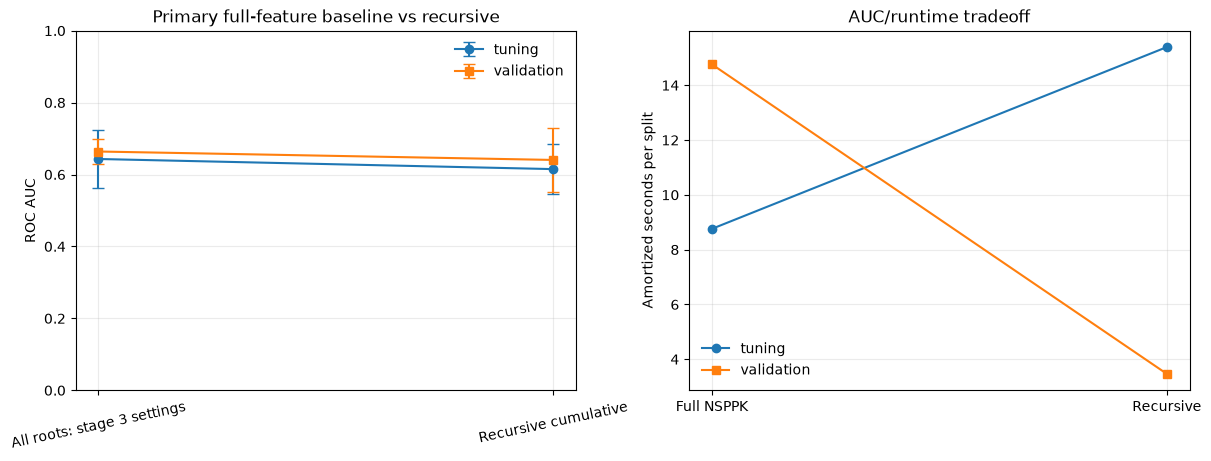

In [6]:
auc_df = pd.DataFrame(baseline_auc_rows + recursive_auc_rows)
auc_summary_df = (
    auc_df.groupby(['cohort', 'configuration'])
    .agg(mean_auc=('ROC AUC', 'mean'), std_auc=('ROC AUC', 'std'),
         mean_feature_nnz=('feature_nnz', 'mean'), split_count=('split', 'count'))
    .reset_index()
)
display(auc_summary_df.round(4))

baseline_runtime_df = pd.DataFrame(baseline_runtime_rows)
baseline_runtime_df['mean_end_to_end_per_split_sec'] = (
    baseline_runtime_df['feature_generation_sec'] / baseline_runtime_df['split_count']
    + baseline_runtime_df['mean_classifier_fit_sec']
    + baseline_runtime_df['mean_prediction_sec']
)
recursive_runtime_df = (
    pd.DataFrame(recursive_runtime_rows)
    .groupby('cohort')
    .agg(mean_fit_sec=('fit_sec', 'mean'), mean_prediction_sec=('prediction_sec', 'mean'),
         mean_end_to_end_sec=('end_to_end_sec', 'mean'), split_count=('split', 'count'))
    .reset_index()
)
display(baseline_runtime_df.round(3))
display(recursive_runtime_df.round(3))

stage_timing_df = (
    pd.DataFrame(recursive_stage_timing_rows)
    .groupby(['cohort', 'stage'])
    .agg(importance_fit_sec=('importance_fit_seconds', 'mean'),
         root_selection_sec=('root_selection_seconds', 'mean'),
         feature_generation_sec=('feature_generation_seconds', 'mean'))
    .reset_index()
)
display(stage_timing_df.round(3))

primary_baseline = 'All roots: stage 3 settings'
plot_auc = auc_summary_df[
    auc_summary_df['configuration'].isin([primary_baseline, 'Recursive cumulative'])
].copy()
plot_runtime_baseline = baseline_runtime_df[
    baseline_runtime_df['configuration'] == primary_baseline
].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for cohort_name, marker in (('tuning', 'o'), ('validation', 's')):
    subset = plot_auc[plot_auc['cohort'] == cohort_name]
    axes[0].errorbar(
        subset['configuration'], subset['mean_auc'], yerr=subset['std_auc'],
        marker=marker, capsize=4, label=cohort_name,
    )
    recursive_time = recursive_runtime_df.loc[
        recursive_runtime_df['cohort'] == cohort_name, 'mean_end_to_end_sec'
    ].iloc[0]
    baseline_time = plot_runtime_baseline.loc[
        plot_runtime_baseline['cohort'] == cohort_name, 'mean_end_to_end_per_split_sec'
    ].iloc[0]
    axes[1].plot(
        ['Full NSPPK', 'Recursive'], [baseline_time, recursive_time],
        marker=marker, label=cohort_name,
    )
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('ROC AUC')
axes[0].set_title('Primary full-feature baseline vs recursive')
axes[0].tick_params(axis='x', rotation=12)
axes[1].set_ylabel('Amortized seconds per split')
axes[1].set_title('AUC/runtime tradeoff')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)


## Interpretation and observed result

The exploratory search favored 10% root retention, importance quantile 0.5, and logistic-regression `C=0.01`. The recursive stages use `(radius=1, distance=4, connector=0)` followed by `(radius=2, distance=4, connector=1)`. Simplex expansion is omitted from recursive stage 2 because adding it increased generation cost without improving AUC in the preliminary search. The search was exploratory rather than nested cross-validation; use the independent validation cohort below to judge the selected setting.

| Cohort | Full all-roots simplex AUC | Recursive cumulative AUC | Full amortized sec/split | Recursive sec/split |
| --- | ---: | ---: | ---: | ---: |
| Tuning (5 splits) | 0.6432 ± 0.0811 | 0.6150 ± 0.0703 | 8.633 | 3.281 |
| Validation (3 splits) | 0.6640 ± 0.0351 | 0.6405 ± 0.0888 | 13.139 | 3.246 |

On these 200-graph balanced cohorts, recursive generation was about 2.6× faster per split on the tuning cohort and 4.0× faster on validation when full-feature generation is amortized across the cohort’s splits. For a single train/test run, the all-roots simplex feature build alone took 42.88 seconds on tuning and 39.29 seconds on validation, compared with 3.28 and 3.25 seconds for recursive fit plus held-out prediction. Recursive mean AUC was lower by 0.028 on tuning and 0.024 on validation. These results support comparable performance with lower runtime on this sampled benchmark, not a claim of higher accuracy or universal superiority.

The all-roots matrix is built once per cohort using the first split’s training graphs, then reused across that cohort’s splits; its build cost is divided by the number of splits in the amortized comparison. Recursive importance selection is refit inside every training split. Diagnostic individual-stage scores are reported separately and excluded from recursive fit-plus-prediction timing.

The sample is balanced at 100 active and 100 inactive graphs. AUC varies across splits, and the validation cohort contains only three splits. Re-run with more samples and repeated seeds before drawing conclusions about the full, imbalanced HIV dataset or other tasks.